# Gaussian bandwidth-choice distributions: exponential symmetric divergences

Compare **L², TV, H², JS, and the sample-specific ISE choice** on the same repeated samples from $N(0,1)$ and the same geometric bandwidth grid.
For every spectral method, use $S_{ij}=\exp(-\lambda D_{ij})$ with **$\lambda=1$** and select the bandwidth at the largest Perron-vector component.
The ISE choice minimizes exact integrated squared error over the same candidate grid.

| Method | Divergence used in the exponential | Calculation |
|---|---|---|
| L² | $\frac12\int(p-q)^2$ | Exact Gaussian KDE inner products |
| TV | $\frac12\int|p-q|$ | Composite trapezoidal integration |
| H² | $\frac12\int(\sqrt p-\sqrt q)^2$ | Composite trapezoidal integration |
| JS | $\frac12\operatorname{KL}(p\Vert(p+q)/2)+\frac12\operatorname{KL}(q\Vert(p+q)/2)$ | Composite trapezoidal integration; natural logarithms |

The L² factor $1/2$ matches the thesis's bandwidth-distribution experiment. TV, H² and JS enter the exponential as **raw divergences**, without conversion to overlap/affinity similarities or JS division by $\log 2$.
Sources: [thesis divergence definitions and quadrature subsection](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex), especially the Hellinger definition, `eq:JS_KL_formula`, and `eq:beta2_exact_formula01`; [shared exact Gaussian implementation](kde_tools/similarities.py); [shared composite trapezoidal implementation](kde_tools/quadrature.py).

Run all cells. The **preview** profile produces a small comparison; **thesis** uses the original Figure 3.5 sample/repetition/grid settings. A checkpoint saves each completed repetition, so rerunning resumes the same configuration.

In [11]:
from __future__ import annotations

import csv
import hashlib
import importlib
import json
import math
import os
import sys
import time
from pathlib import Path

working_directory = Path.cwd().resolve()
code_directory = next(
    (candidate.resolve()
     for root in (working_directory, *working_directory.parents)
     for candidate in (root, root / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from the project or Code/Code_kde folder.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))
os.environ.setdefault("MPLCONFIGDIR", str(code_directory / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta, gaussian_mise_oracle_bandwidth
from kde_tools.density import exact_oracle_ise_values, gaussian_kde_values
from kde_tools.pdf_export import enable_automatic_pdf_saving
# Refresh source changes when rerunning setup in an existing notebook kernel.
# See https://docs.python.org/3/library/importlib.html#importlib.reload.
import kde_tools.quadrature as _quadrature
importlib.reload(_quadrature)
from kde_tools.quadrature import quadrature_js_divergence_matrix, quadrature_grid_for_kdes, trapezoidal_integral
from kde_tools.similarities import beta2_divergence_matrix, spectral_choice_from_similarity

notebook_name = "gaussian_symmetric_divergence_bandwidth_distributions"
pdf_output_directory = enable_automatic_pdf_saving(
    notebook_name, output_root=code_directory / "outputs" / "pdfs"
)
data_output_directory = code_directory / "outputs" / "data" / notebook_name
image_output_directory = code_directory / "outputs" / "images" / notebook_name
for directory in (data_output_directory, image_output_directory):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Automatic PDF exports: {pdf_output_directory}")

Automatic PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/gaussian_symmetric_divergence_bandwidth_distributions


## Settings

Both profiles draw $n=200$ observations from $N(0,1)$ and use $\lambda=1$, $h_{\min}=0.01$, $h_{\max}=2$. The preview uses $M=20$, $N=21$; the thesis profile uses $M=1000$, $N=201$, matching the [Figure 3.5 caption](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).
`m_x` is the number of shared spatial nodes for TV, H², and JS. All settings are editable below.

The interval $[X_{\min}-Lh_{\max},X_{\max}+Lh_{\max}]$ follows the thesis's truncation construction. The Gaussian tail-mass bound $\delta_L=2\Phi(-L)$ also bounds the omitted tails of the TV and H² integrands: pointwise, each is at most $(p+q)/2$ (direct deduction from their definitions). This controls **tail truncation only**. Spatial discretization errors still require refinement checks; no total error certificate is claimed.
Sources: [thesis quadrature subsection, truncation bounds](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex); [official composite trapezoidal documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html).

In [12]:
RUN_PROFILE = "thesis"  # "preview" or "thesis"
PROFILES = {
    "preview": {"sample_size": 200, "repetitions": 20, "grid_size": 21},
    "thesis": {"sample_size": 200, "repetitions": 1000, "grid_size": 201},
}
settings = {
    **PROFILES[RUN_PROFILE],
    "sigma2": 1.0,
    "lambda_value": 1.0,
    "h_min": 0.01,
    "h_max": 2.0,
    "m_x": 6001,
    "padding": 6.0,
    "base_seed": 910_000,
    "implementation_version": 2,
    "js_quadrature": "composite_trapezoidal",
}
reuse_checkpoint = True
show_mise_reference = True

if settings["sample_size"] < 1 or settings["repetitions"] < 1:
    raise ValueError("sample_size and repetitions must be positive.")
if settings["sigma2"] <= 0 or settings["lambda_value"] <= 0:
    raise ValueError("sigma2 and lambda_value must be positive.")
h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=settings["h_min"], h_max=settings["h_max"],
    beta=2.0, grid_size=settings["grid_size"],
)
methods = ("L2", "TV", "H2", "JS", "ISE")
configuration_json = json.dumps(settings, sort_keys=True)
configuration_id = hashlib.sha256(configuration_json.encode()).hexdigest()[:12]
run_directory = data_output_directory / RUN_PROFILE / configuration_id
run_directory.mkdir(parents=True, exist_ok=True)
checkpoint_path = run_directory / "checkpoint.npz"
plot_stem = f"{RUN_PROFILE}_n{settings['sample_size']}_M{settings['repetitions']}_N{len(h_grid)}"
tail_mass_bound = math.erfc(settings["padding"] / math.sqrt(2.0))
print(f"Profile: {RUN_PROFILE}; n={settings['sample_size']}, M={settings['repetitions']}, N={len(h_grid)}, lambda={settings['lambda_value']:g}")
print(f"TV/H² tail truncation bound: {tail_mass_bound:.3e}; spatial nodes: {settings['m_x']}")
print("JS uses composite trapezoidal integration on the same grid as TV/H².")
print(f"Checkpoint and data: {run_directory}")

Profile: thesis; n=200, M=1000, N=201, lambda=1
TV/H² tail truncation bound: 1.973e-09; spatial nodes: 6001
JS uses composite trapezoidal integration on the same grid as TV/H².
Checkpoint and data: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/gaussian_symmetric_divergence_bandwidth_distributions/thesis/72276652894b


## One repetition: four exponential spectral choices and one ISE choice

The same sample supplies all five choices. L² uses the shared exact divergence. TV, H², and JS integrate the original KDEs over the same truncated interval and reuse a single density evaluation, without renormalizing the densities on that interval. JS uses the shared composite trapezoidal divergence routine with natural logarithms.
The H² calculation below is the algebraic expansion of $\frac12\int(\sqrt p-\sqrt q)^2$; the trapezoidal weights are $\Delta x/2$ at the endpoints and $\Delta x$ inside. Sources: [thesis composite trapezoidal rule](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex), [official trapezoidal integration documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html).

In [13]:
def compute_divergences(samples, h_grid, *, m_x, padding):
    """Build raw L², TV, H², JS matrices for the same Gaussian KDE family."""
    x_grid = quadrature_grid_for_kdes(samples, h_grid, m_x=m_x, padding=padding)
    densities = gaussian_kde_values(samples, h_grid, x_grid)
    masses = trapezoidal_integral(densities, x_grid, axis=1)
    number_of_bandwidths = len(h_grid)

    tv = np.zeros((number_of_bandwidths, number_of_bandwidths))
    for i in range(number_of_bandwidths - 1):
        values = 0.5 * trapezoidal_integral(
            np.abs(densities[i + 1:] - densities[i]), x_grid, axis=1
        )
        tv[i, i + 1:] = values
        tv[i + 1:, i] = values

    weights = np.full(len(x_grid), (x_grid[-1] - x_grid[0]) / (len(x_grid) - 1))
    weights[[0, -1]] *= 0.5
    square_roots = np.sqrt(densities)
    affinity = (square_roots * weights[None, :]) @ square_roots.T
    h_squared = np.maximum(0.5 * (masses[:, None] + masses[None, :]) - affinity, 0.0)

    divergences = {
        "L2": beta2_divergence_matrix(samples, h_grid),
        "TV": tv,
        "H2": h_squared,
        "JS": quadrature_js_divergence_matrix(densities, x_grid),
    }
    for name, divergence in divergences.items():
        divergence[:] = 0.5 * (divergence + divergence.T)
        np.fill_diagonal(divergence, 0.0)
        if not np.all(np.isfinite(divergence)) or np.any(divergence < 0):
            raise ArithmeticError(f"Invalid {name} divergence matrix.")
    diagnostics = {"maximum_grid_mass_error": float(np.max(np.abs(masses - 1.0)))}
    return divergences, diagnostics


def select_one_sample(samples, h_grid, settings):
    divergences, diagnostics = compute_divergences(
        samples, h_grid, m_x=settings["m_x"], padding=settings["padding"],
    )
    selections = {}
    for name, divergence in divergences.items():
        similarity = np.exp(-settings["lambda_value"] * divergence)
        np.fill_diagonal(similarity, 1.0)
        selections[name] = int(spectral_choice_from_similarity(similarity)["selected_index"])
    ise_values = exact_oracle_ise_values(samples, h_grid, settings["sigma2"])
    selections["ISE"] = int(np.argmin(ise_values))
    selected_ise = {name: float(ise_values[index]) for name, index in selections.items()}
    return selections, selected_ise, diagnostics

## Repeated sampling, with resumable checkpoints

Each repetition uses seed `base_seed + repetition`, independently of which methods are computed. The checkpoint contains the settings and all completed five-method choices. Changing numerical settings creates a new run directory. Set `reuse_checkpoint=False` to recompute the current configuration.

In [14]:
repetitions = settings["repetitions"]
selected_indices = np.full((repetitions, len(methods)), -1, dtype=int)
selected_ise_values = np.full((repetitions, len(methods)), np.nan)
grid_mass_errors = np.full(repetitions, np.nan)
completed = 0
if reuse_checkpoint and checkpoint_path.exists():
    with np.load(checkpoint_path, allow_pickle=False) as checkpoint:
        if str(checkpoint["configuration_json"].item()) != configuration_json:
            raise ValueError("Checkpoint settings differ from the current configuration.")
        completed = int(checkpoint["completed"].item())
        selected_indices[:] = checkpoint["selected_indices"]
        selected_ise_values[:] = checkpoint["selected_ise_values"]
        grid_mass_errors[:] = checkpoint["grid_mass_errors"]
    if not 0 <= completed <= repetitions or np.any(selected_indices[:completed] < 0):
        raise ValueError("Checkpoint has invalid completed selections.")
    print(f"Resuming after {completed}/{repetitions} completed repetitions.")

started = time.perf_counter()
for repetition in range(completed, repetitions):
    rng = np.random.default_rng(settings["base_seed"] + repetition)
    samples = rng.normal(0.0, np.sqrt(settings["sigma2"]), size=settings["sample_size"])
    choices, ise_values, diagnostics = select_one_sample(samples, h_grid, settings)
    selected_indices[repetition] = [choices[name] for name in methods]
    selected_ise_values[repetition] = [ise_values[name] for name in methods]
    grid_mass_errors[repetition] = diagnostics["maximum_grid_mass_error"]
    temporary_checkpoint = checkpoint_path.with_suffix(".npz.tmp")
    with temporary_checkpoint.open("wb") as stream:
        np.savez_compressed(
            stream, configuration_json=configuration_json, completed=repetition + 1,
            selected_indices=selected_indices, selected_ise_values=selected_ise_values,
            grid_mass_errors=grid_mass_errors,
        )
    temporary_checkpoint.replace(checkpoint_path)
    print(f"Completed {repetition + 1}/{repetitions}; elapsed this run: {time.perf_counter() - started:.1f}s", flush=True)

counts = {name: np.bincount(selected_indices[:, column], minlength=len(h_grid))
          for column, name in enumerate(methods)}
frequencies = {name: values / repetitions for name, values in counts.items()}
for name in methods:
    assert counts[name].sum() == repetitions
    assert np.isclose(frequencies[name].sum(), 1.0)
assert np.all(selected_ise_values[:, -1, None] <= selected_ise_values + 1e-12)
print(f"Maximum observed grid mass error: {np.max(grid_mass_errors):.3e}")

Completed 1/1000; elapsed this run: 12.0s
Completed 2/1000; elapsed this run: 23.5s
Completed 3/1000; elapsed this run: 34.9s
Completed 4/1000; elapsed this run: 46.3s
Completed 5/1000; elapsed this run: 58.3s
Completed 6/1000; elapsed this run: 69.3s
Completed 7/1000; elapsed this run: 81.1s
Completed 8/1000; elapsed this run: 92.1s
Completed 9/1000; elapsed this run: 103.0s
Completed 10/1000; elapsed this run: 114.1s
Completed 11/1000; elapsed this run: 125.9s
Completed 12/1000; elapsed this run: 137.8s
Completed 13/1000; elapsed this run: 149.0s


KeyboardInterrupt: 

## Summary and saved data

The table reports selected bandwidths and the exact ISE evaluated at each choice. Export the individual choices, frequency table, summary, and settings so that the plotted distributions can be reproduced without rerunning the integrations.

In [5]:
def write_csv(path, fieldnames, rows):
    with path.open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

selection_rows = [
    {"repetition": repetition, "seed": settings["base_seed"] + repetition,
     "method": name, "grid_index": int(selected_indices[repetition, column]),
     "h": float(h_grid[selected_indices[repetition, column]]),
     "ise": float(selected_ise_values[repetition, column])}
    for repetition in range(repetitions) for column, name in enumerate(methods)
]
frequency_rows = [
    {"method": name, "grid_index": index, "h": float(h_grid[index]),
     "count": int(counts[name][index]), "relative_frequency": float(frequencies[name][index])}
    for name in methods for index in range(len(h_grid))
]
summary_rows = []
for column, name in enumerate(methods):
    selected_h = h_grid[selected_indices[:, column]]
    modal_index = int(np.argmax(counts[name]))
    summary_rows.append({
        "method": name, "modal_h": float(h_grid[modal_index]),
        "mean_h": float(np.mean(selected_h)), "median_h": float(np.median(selected_h)),
        "modal_frequency": float(frequencies[name][modal_index]),
        "mean_ise": float(np.mean(selected_ise_values[:, column])),
    })
write_csv(run_directory / "selections.csv", selection_rows[0].keys(), selection_rows)
write_csv(run_directory / "frequencies.csv", frequency_rows[0].keys(), frequency_rows)
write_csv(run_directory / "summary.csv", summary_rows[0].keys(), summary_rows)
(run_directory / "settings.json").write_text(json.dumps({
    "profile": RUN_PROFILE, "settings": settings, "methods": list(methods),
    "tail_mass_bound": tail_mass_bound, "maximum_grid_mass_error": float(np.max(grid_mass_errors)),
}, indent=2) + "\n")
print(f"{'method':8s} {'modal h':>10s} {'mean h':>10s} {'median h':>10s} {'mean ISE':>12s}")
for row in summary_rows:
    print(f"{row['method']:8s} {row['modal_h']:10.5f} {row['mean_h']:10.5f} {row['median_h']:10.5f} {row['mean_ise']:12.6f}")
print(f"CSV data and settings saved to {run_directory}")

method      modal h     mean h   median h     mean ISE
L2          0.08326    0.09248    0.08326     0.014067
TV          0.14142    0.13117    0.14142     0.009535
H2          0.14142    0.16645    0.14142     0.008733
JS          0.08326    0.11977    0.10851     0.011504
ISE         0.40806    0.39957    0.40806     0.003249
CSV data and settings saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/gaussian_symmetric_divergence_bandwidth_distributions/preview/cdee002ceca3


## Bandwidth-choice distribution figure

Overlaid bars show the five relative-frequency distributions. As in Figure 3.5, the horizontal positions are equally spaced geometric-grid indices, labeled with their bandwidth values. The optional dashed line shows the Gaussian population MISE optimum; the purple bars show the **sample-specific ISE choice**.
The title records the actual $n$, $M$, $N$, and $\lambda$, so a preview is distinguishable from the larger simulation. Every displayed figure is automatically exported to PDF; a PNG is also saved for inspection.
Source for the optional reference: [exact Gaussian MISE helper](kde_tools/bandwidths.py).

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/gaussian_symmetric_divergence_bandwidth_distributions/001_bandwidth_choice_distributions_gaussian_data_n_200_m_20_n_21_s_exp_lambda_d_lamb.pdf
PNG: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/gaussian_symmetric_divergence_bandwidth_distributions/preview_n200_M20_N21.png
PDF directory: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/gaussian_symmetric_divergence_bandwidth_distributions


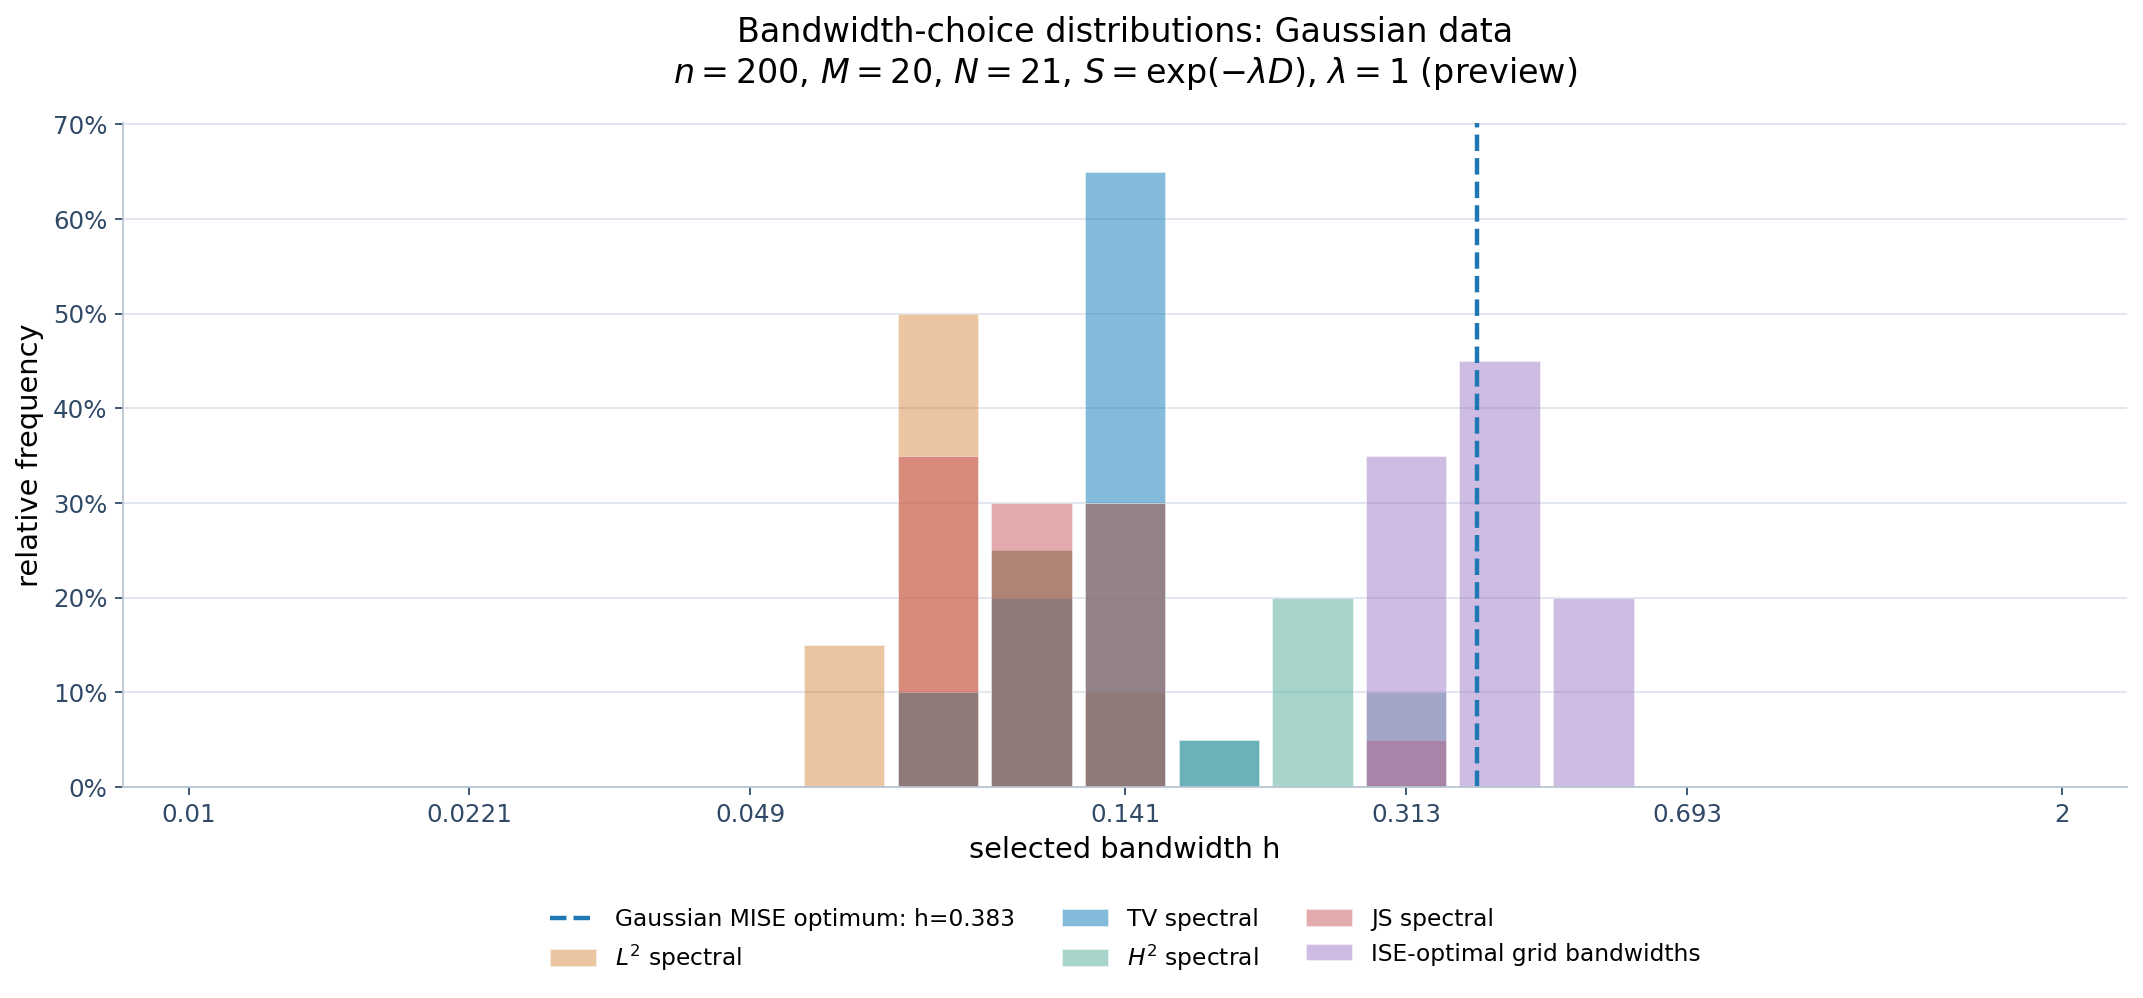

In [6]:
colors = {"L2": "#D6843B", "TV": "#0072B2", "H2": "#49A994", "JS": "#C44E52", "ISE": "#9B73C5"}
labels = {"L2": r"$L^2$ spectral", "TV": "TV spectral", "H2": r"$H^2$ spectral", "JS": "JS spectral", "ISE": "ISE-optimal grid bandwidths"}
grid_positions = np.arange(len(h_grid))
fig, ax = plt.subplots(figsize=(13.5, 6.5))
for name in methods:
    ax.bar(grid_positions, frequencies[name], width=0.86, color=colors[name],
           alpha=0.48, edgecolor="white", linewidth=0.35, label=labels[name])
if show_mise_reference:
    mise_bandwidth = np.sqrt(settings["sigma2"]) * gaussian_mise_oracle_bandwidth(settings["sample_size"])
    if h_grid[0] <= mise_bandwidth <= h_grid[-1]:
        mise_position = np.interp(np.log(mise_bandwidth), np.log(h_grid), grid_positions)
        ax.axvline(mise_position, color="#1f77b4", linestyle="--", linewidth=2.0,
                   label=f"Gaussian MISE optimum: h={mise_bandwidth:.3f}")
ticks = np.unique(np.linspace(0, len(h_grid) - 1, 7, dtype=int))
ax.set_xticks(ticks, [f"{h_grid[index]:.3g}" for index in ticks])
ax.set_xlim(-0.7, len(h_grid) - 0.3)
ax.set_ylim(0, 1.08 * max(np.max(values) for values in frequencies.values()))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
ax.set_xlabel("selected bandwidth h", fontsize=13)
ax.set_ylabel("relative frequency", fontsize=13)
ax.set_title(
    "Bandwidth-choice distributions: Gaussian data\n"
    + rf"$n={settings['sample_size']}$, $M={repetitions}$, $N={len(h_grid)}$, "
    + rf"$S=\exp(-\lambda D)$, $\lambda={settings['lambda_value']:g}$ ({RUN_PROFILE})",
    fontsize=15, pad=18,
)
ax.grid(axis="y", color="#DDE5EC", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#B8C5D1")
ax.tick_params(labelsize=11, colors="#304967")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=10.5)
fig.tight_layout()
png_output_path = image_output_directory / f"{plot_stem}.png"
fig.savefig(png_output_path, dpi=160, bbox_inches="tight")
plt.show()  # The shared automatic exporter saves the PDF before display.
print(f"PNG: {png_output_path}")
print(f"PDF directory: {pdf_output_directory}")